In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

BASE = Path("/home/ec2-user/SageMaker/bach_lab")

TRAIN_DIR = BASE / "train"
VALID_DIR = BASE / "valid"
TEST_DIR = BASE / "test"

print("Train:", len(list(TRAIN_DIR.glob("*.csv"))))
print("Valid:", len(list(VALID_DIR.glob("*.csv"))))
print("Test :", len(list(TEST_DIR.glob("*.csv"))))

Train: 229
Valid: 76
Test : 77


In [2]:
def revisar_particion(carpeta):
    archivos = sorted(carpeta.glob("*.csv"))

    longitudes = []
    min_val = 999
    max_val = -999

    for archivo in archivos:
        df = pd.read_csv(archivo)

        assert list(df.columns) == ["note0", "note1", "note2", "note3"]

        longitudes.append(len(df))

        min_val = min(min_val, df.values.min())
        max_val = max(max_val, df.values.max())

    return {
        "corales": len(archivos),
        "longitud_min": min(longitudes),
        "longitud_max": max(longitudes),
        "valor_min": min_val,
        "valor_max": max_val
    }

print("TRAIN:", revisar_particion(TRAIN_DIR))
print("VALID:", revisar_particion(VALID_DIR))
print("TEST :", revisar_particion(TEST_DIR))

TRAIN: {'corales': 229, 'longitud_min': 100, 'longitud_max': 516, 'valor_min': np.int64(0), 'valor_max': np.int64(81)}
VALID: {'corales': 76, 'longitud_min': 128, 'longitud_max': 576, 'valor_min': np.int64(0), 'valor_max': np.int64(81)}
TEST : {'corales': 77, 'longitud_min': 128, 'longitud_max': 640, 'valor_min': np.int64(0), 'valor_max': np.int64(81)}


In [3]:
archivo = sorted(TRAIN_DIR.glob("*.csv"))[0]
df = pd.read_csv(archivo)

print("Archivo:", archivo.name)
print("Forma:", df.shape)
display(df.head(10))

Archivo: chorale_000.csv
Forma: (192, 4)


,note0,note1,note2,note3
0,74,70,65,58
1,74,70,65,58
2,74,70,65,58
3,74,70,65,58
4,75,70,58,55
5,75,70,58,55
6,75,70,60,55
7,75,70,60,55
8,77,69,62,50
9,77,69,62,50


In [4]:
def crear_ventanas(carpeta, stride):
    archivos = sorted(carpeta.glob("*.csv"))

    X_list = []
    Y_list = []

    for archivo in archivos:
        df = pd.read_csv(archivo)
        datos = df[["note0", "note1", "note2", "note3"]].values.astype(np.int64)

        # Ventanas completas de 48 pasos
        for inicio in range(0, len(datos) - 48 + 1, stride):
            ventana = datos[inicio:inicio + 48]

            X = ventana[:32]   # contexto
            Y = ventana[32:]   # 16 pasos futuros

            X_list.append(X)
            Y_list.append(Y)

    X = np.stack(X_list)
    Y = np.stack(Y_list)

    return X, Y

In [5]:
X_train, Y_train = crear_ventanas(TRAIN_DIR, stride=8)
X_valid, Y_valid = crear_ventanas(VALID_DIR, stride=16)
X_test,  Y_test  = crear_ventanas(TEST_DIR, stride=16)

print("TRAIN:", X_train.shape, Y_train.shape)
print("VALID:", X_valid.shape, Y_valid.shape)
print("TEST :", X_test.shape, Y_test.shape)

TRAIN: (5681, 32, 4) (5681, 16, 4)
VALID: (982, 32, 4) (982, 16, 4)
TEST : (1011, 32, 4) (1011, 16, 4)


In [6]:
print("Ejemplo X:", X_train[0].shape)
print("Ejemplo Y:", Y_train[0].shape)

print("\nÚltimo paso del contexto X:")
print(X_train[0, -1])

print("\nPrimer paso futuro Y:")
print(Y_train[0, 0])

print("\nRango train X:",
      X_train.min(), X_train.max())

print("Rango train Y:",
      Y_train.min(), Y_train.max())

Ejemplo X: (32, 4)
Ejemplo Y: (16, 4)

Último paso del contexto X:
[72 69 65 53]

Primer paso futuro Y:
[74 70 65 46]

Rango train X: 0 81
Rango train Y: 0 81


In [7]:
import torch
from torch.utils.data import TensorDataset, DataLoader

# Convertir a tensores
X_train_t = torch.tensor(X_train, dtype=torch.long)
Y_train_t = torch.tensor(Y_train, dtype=torch.long)

X_valid_t = torch.tensor(X_valid, dtype=torch.long)
Y_valid_t = torch.tensor(Y_valid, dtype=torch.long)

X_test_t = torch.tensor(X_test, dtype=torch.long)
Y_test_t = torch.tensor(Y_test, dtype=torch.long)

# Dataset
train_ds = TensorDataset(X_train_t, Y_train_t)
valid_ds = TensorDataset(X_valid_t, Y_valid_t)
test_ds = TensorDataset(X_test_t, Y_test_t)

# DataLoader
BATCH_SIZE = 64

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True
)

valid_loader = DataLoader(
    valid_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Train batches:", len(train_loader))
print("Valid batches:", len(valid_loader))
print("Test batches :", len(test_loader))

Train batches: 89
Valid batches: 16
Test batches : 16


In [8]:
xb, yb = next(iter(train_loader))

print("X batch:", xb.shape)
print("Y batch:", yb.shape)
print("dtype X:", xb.dtype)
print("dtype Y:", yb.dtype)

X batch: torch.Size([64, 32, 4])
Y batch: torch.Size([64, 16, 4])
dtype X: torch.int64
dtype Y: torch.int64


In [9]:
import torch.nn as nn

VOCAB_SIZE = 128
EMBED_DIM = 16
HIDDEN_DIM = 128
NUM_LAYERS = 1
OUTPUT_STEPS = 16
NUM_VOICES = 4

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [10]:
class EncoderLSTM(nn.Module):
    def __init__(
        self,
        vocab_size=128,
        embed_dim=16,
        hidden_dim=128,
        num_layers=1
    ):
        super().__init__()

        self.embeddings = nn.ModuleList([
            nn.Embedding(vocab_size, embed_dim)
            for _ in range(NUM_VOICES)
        ])

        self.lstm = nn.LSTM(
            input_size=embed_dim * NUM_VOICES,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True
        )

    def forward(self, x):
        # x: (batch, 32, 4)

        emb = [
            self.embeddings[v](x[:, :, v])
            for v in range(NUM_VOICES)
        ]

        # Cada voz: (batch, 32, 16)
        # Concatenación: (batch, 32, 64)
        x_emb = torch.cat(emb, dim=-1)

        outputs, (h, c) = self.lstm(x_emb)

        return outputs, h, c

In [11]:
class DecoderLSTM(nn.Module):
    def __init__(
        self,
        vocab_size=128,
        embed_dim=16,
        hidden_dim=128,
        num_layers=1
    ):
        super().__init__()

        self.embeddings = nn.ModuleList([
            nn.Embedding(vocab_size, embed_dim)
            for _ in range(NUM_VOICES)
        ])

        self.lstm = nn.LSTM(
            input_size=embed_dim * NUM_VOICES,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True
        )

        self.output_layers = nn.ModuleList([
            nn.Linear(hidden_dim, vocab_size)
            for _ in range(NUM_VOICES)
        ])

    def forward_step(self, x_step, h, c):
        # x_step: (batch, 4)

        emb = [
            self.embeddings[v](x_step[:, v])
            for v in range(NUM_VOICES)
        ]

        # (batch, 64)
        x_emb = torch.cat(emb, dim=-1)

        # LSTM espera dimensión temporal
        x_emb = x_emb.unsqueeze(1)

        output, (h, c) = self.lstm(x_emb, (h, c))

        # (batch, hidden)
        output = output[:, 0, :]

        logits = torch.stack(
            [layer(output) for layer in self.output_layers],
            dim=1
        )

        # logits: (batch, 4, 128)

        return logits, h, c

In [12]:
class Seq2SeqLSTM(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = EncoderLSTM()
        self.decoder = DecoderLSTM()

    def forward(self, x, y=None, teacher_forcing=True):
        # x: (batch, 32, 4)
        # y: (batch, 16, 4)

        encoder_outputs, h, c = self.encoder(x)

        # Primer input del decoder:
        # último paso del contexto X
        decoder_input = x[:, -1, :]

        logits_steps = []

        for t in range(OUTPUT_STEPS):

            logits, h, c = self.decoder.forward_step(
                decoder_input,
                h,
                c
            )

            logits_steps.append(logits)

            if teacher_forcing and y is not None:
                # Para t=0 usamos después y[:,0]
                # Para el último paso ya no importa el siguiente input
                decoder_input = y[:, t, :]
            else:
                # generación libre
                decoder_input = logits.argmax(dim=-1)

        return torch.stack(logits_steps, dim=1)

In [13]:
model_e1 = Seq2SeqLSTM().to(device)

xb, yb = next(iter(train_loader))

xb = xb.to(device)
yb = yb.to(device)

with torch.no_grad():
    logits = model_e1(
        xb,
        yb,
        teacher_forcing=True
    )

print("Input X :", xb.shape)
print("Target Y:", yb.shape)
print("Logits  :", logits.shape)

Input X : torch.Size([64, 32, 4])
Target Y: torch.Size([64, 16, 4])
Logits  : torch.Size([64, 16, 4, 128])


In [14]:
criterion = nn.CrossEntropyLoss()

def calcular_loss(logits, targets):
    # logits:  (batch, 16, 4, 128)
    # targets: (batch, 16, 4)

    logits_flat = logits.reshape(-1, VOCAB_SIZE)
    targets_flat = targets.reshape(-1)

    loss = criterion(logits_flat, targets_flat)

    return loss

In [15]:
def accuracy_por_nota(logits, targets):
    pred = logits.argmax(dim=-1)

    correctas = (pred == targets).sum().item()
    total = targets.numel()

    return correctas / total

In [16]:
def accuracy_por_paso(logits, targets):
    pred = logits.argmax(dim=-1)

    # (batch, 16)
    paso_correcto = (pred == targets).all(dim=-1)

    correctos = paso_correcto.sum().item()
    total = paso_correcto.numel()

    return correctos / total

In [17]:
with torch.no_grad():
    logits = model_e1(xb, yb, teacher_forcing=True)

loss = calcular_loss(logits, yb)
acc_nota = accuracy_por_nota(logits, yb)
acc_paso = accuracy_por_paso(logits, yb)

print("Loss:", loss.item())
print("Accuracy por nota:", acc_nota)
print("Accuracy por paso:", acc_paso)

Loss: 4.86647891998291
Accuracy por nota: 0.00439453125
Accuracy por paso: 0.0


In [18]:
import random
import time
import copy

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

optimizer = torch.optim.Adam(
    model_e1.parameters(),
    lr=1e-3
)

MAX_EPOCHS = 20
PATIENCE = 4

best_val_loss = float("inf")
best_epoch = 0
best_state = None
epochs_without_improvement = 0

history_e1 = {
    "train_loss": [],
    "val_loss": [],
    "val_acc_nota": [],
    "val_acc_paso": []
}

inicio_total = time.time()

In [19]:
for epoch in range(1, MAX_EPOCHS + 1):

    # =========================
    # ENTRENAMIENTO
    # =========================
    model_e1.train()

    train_loss_sum = 0.0
    train_examples = 0

    for xb, yb in train_loader:

        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        logits = model_e1(
            xb,
            yb,
            teacher_forcing=True
        )

        loss = calcular_loss(logits, yb)

        loss.backward()
        optimizer.step()

        batch_size = xb.size(0)

        train_loss_sum += loss.item() * batch_size
        train_examples += batch_size

    train_loss = train_loss_sum / train_examples

    # =========================
    # VALIDACIÓN
    # =========================
    model_e1.eval()

    val_loss_sum = 0.0
    val_examples = 0

    notas_correctas = 0
    notas_totales = 0

    pasos_correctos = 0
    pasos_totales = 0

    with torch.no_grad():

        for xb, yb in valid_loader:

            xb = xb.to(device)
            yb = yb.to(device)

            logits = model_e1(
                xb,
                yb,
                teacher_forcing=True
            )

            loss = calcular_loss(logits, yb)

            batch_size = xb.size(0)

            val_loss_sum += loss.item() * batch_size
            val_examples += batch_size

            pred = logits.argmax(dim=-1)

            notas_correctas += (
                pred == yb
            ).sum().item()

            notas_totales += yb.numel()

            paso_correcto = (
                pred == yb
            ).all(dim=-1)

            pasos_correctos += paso_correcto.sum().item()
            pasos_totales += paso_correcto.numel()

    val_loss = val_loss_sum / val_examples

    val_acc_nota = notas_correctas / notas_totales
    val_acc_paso = pasos_correctos / pasos_totales

    # Guardar historial
    history_e1["train_loss"].append(train_loss)
    history_e1["val_loss"].append(val_loss)
    history_e1["val_acc_nota"].append(val_acc_nota)
    history_e1["val_acc_paso"].append(val_acc_paso)

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Acc Nota: {val_acc_nota:.4f} | "
        f"Acc Paso: {val_acc_paso:.4f}"
    )

    # =========================
    # EARLY STOPPING
    # =========================
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        best_epoch = epoch

        best_state = copy.deepcopy(
            model_e1.state_dict()
        )

        epochs_without_improvement = 0

        print("  -> Nuevo mejor checkpoint")

    else:

        epochs_without_improvement += 1

        print(
            f"  -> Sin mejora "
            f"({epochs_without_improvement}/{PATIENCE})"
        )

        if epochs_without_improvement >= PATIENCE:
            print("Early stopping.")
            break

Epoch 01 | Train Loss: 2.8021 | Val Loss: 2.0890 | Acc Nota: 0.4411 | Acc Paso: 0.0677
  -> Nuevo mejor checkpoint
Epoch 02 | Train Loss: 1.7465 | Val Loss: 1.5373 | Acc Nota: 0.6219 | Acc Paso: 0.2563
  -> Nuevo mejor checkpoint
Epoch 03 | Train Loss: 1.3542 | Val Loss: 1.2652 | Acc Nota: 0.6993 | Acc Paso: 0.4078
  -> Nuevo mejor checkpoint
Epoch 04 | Train Loss: 1.1639 | Val Loss: 1.1227 | Acc Nota: 0.7309 | Acc Paso: 0.4891
  -> Nuevo mejor checkpoint
Epoch 05 | Train Loss: 1.0593 | Val Loss: 1.0382 | Acc Nota: 0.7500 | Acc Paso: 0.5315
  -> Nuevo mejor checkpoint
Epoch 06 | Train Loss: 0.9952 | Val Loss: 0.9823 | Acc Nota: 0.7605 | Acc Paso: 0.5574
  -> Nuevo mejor checkpoint
Epoch 07 | Train Loss: 0.9505 | Val Loss: 0.9444 | Acc Nota: 0.7681 | Acc Paso: 0.5798
  -> Nuevo mejor checkpoint
Epoch 08 | Train Loss: 0.9158 | Val Loss: 0.9154 | Acc Nota: 0.7717 | Acc Paso: 0.5879
  -> Nuevo mejor checkpoint
Epoch 09 | Train Loss: 0.8874 | Val Loss: 0.8926 | Acc Nota: 0.7754 | Acc Paso: 

In [20]:
tiempo_e1 = time.time() - inicio_total

print("\n===== RESULTADO E1 =====")
print("Mejor época:", best_epoch)
print("Mejor Val Loss:", best_val_loss)
print("Tiempo total:", tiempo_e1, "segundos")


===== RESULTADO E1 =====
Mejor época: 20
Mejor Val Loss: 0.7604350984217921
Tiempo total: 156.97895550727844 segundos


In [21]:
model_e1.load_state_dict(best_state)

torch.save(
    {
        "model_state_dict": best_state,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "config": {
            "architecture": "LSTM",
            "vocab_size": VOCAB_SIZE,
            "embed_dim": EMBED_DIM,
            "hidden_dim": HIDDEN_DIM,
            "num_layers": NUM_LAYERS,
            "batch_size": BATCH_SIZE,
            "learning_rate": 1e-3,
            "seed": SEED,
            "context_steps": 32,
            "output_steps": 16
        }
    },
    BASE / "E1_best_lstm.pt"
)

print("Checkpoint guardado.")

Checkpoint guardado.


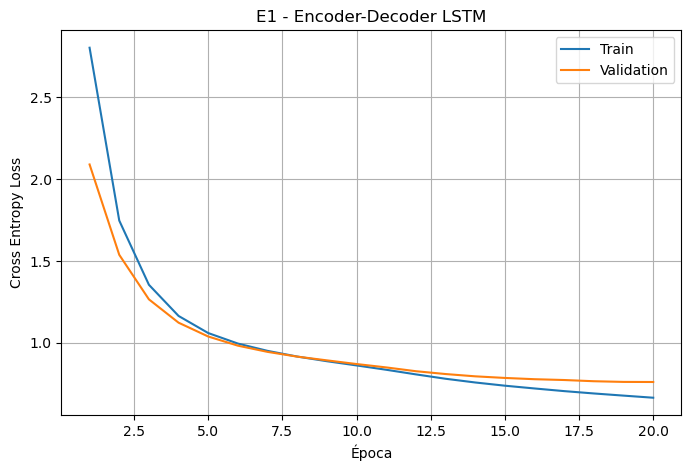

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(history_e1["train_loss"]) + 1),
    history_e1["train_loss"],
    label="Train"
)

plt.plot(
    range(1, len(history_e1["val_loss"]) + 1),
    history_e1["val_loss"],
    label="Validation"
)

plt.xlabel("Época")
plt.ylabel("Cross Entropy Loss")
plt.title("E1 - Encoder-Decoder LSTM")
plt.legend()
plt.grid()

plt.savefig(
    BASE / "E1_curva_loss.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [23]:
model_e1.load_state_dict(best_state)

<All keys matched successfully>

In [24]:
def evaluar_modelo(model, loader):
    model.eval()

    loss_sum = 0.0
    examples = 0

    notas_correctas = 0
    notas_totales = 0

    pasos_correctos = 0
    pasos_totales = 0

    with torch.no_grad():

        for xb, yb in loader:

            xb = xb.to(device)
            yb = yb.to(device)

            logits = model(
                xb,
                yb,
                teacher_forcing=True
            )

            loss = calcular_loss(logits, yb)

            batch_size = xb.size(0)

            loss_sum += loss.item() * batch_size
            examples += batch_size

            pred = logits.argmax(dim=-1)

            notas_correctas += (pred == yb).sum().item()
            notas_totales += yb.numel()

            paso_correcto = (pred == yb).all(dim=-1)

            pasos_correctos += paso_correcto.sum().item()
            pasos_totales += paso_correcto.numel()

    return {
        "loss": loss_sum / examples,
        "acc_nota": notas_correctas / notas_totales,
        "acc_paso": pasos_correctos / pasos_totales
    }

metricas_e1 = evaluar_modelo(model_e1, valid_loader)

print(metricas_e1)

{'loss': 0.7604350984217921, 'acc_nota': 0.7882351069246436, 'acc_paso': 0.597632382892057}


In [25]:
params_e1 = sum(
    p.numel()
    for p in model_e1.parameters()
    if p.requires_grad
)

print("Parámetros entrenables E1:", params_e1)

Parámetros entrenables E1: 281088


In [26]:
resultado_e1 = {
    "experimento": "E1",
    "arquitectura": "Encoder-Decoder LSTM",
    "atencion": False,
    "hidden_dim": HIDDEN_DIM,
    "embedding_dim": EMBED_DIM,
    "num_layers": NUM_LAYERS,
    "batch_size": BATCH_SIZE,
    "learning_rate": 1e-3,
    "seed": 42,
    "mejor_epoca": best_epoch,
    "val_loss": metricas_e1["loss"],
    "val_acc_nota": metricas_e1["acc_nota"],
    "val_acc_paso": metricas_e1["acc_paso"],
    "parametros": params_e1,
    "tiempo_segundos": tiempo_e1
}

resultado_e1

{'experimento': 'E1',
 'arquitectura': 'Encoder-Decoder LSTM',
 'atencion': False,
 'hidden_dim': 128,
 'embedding_dim': 16,
 'num_layers': 1,
 'batch_size': 64,
 'learning_rate': 0.001,
 'seed': 42,
 'mejor_epoca': 20,
 'val_loss': 0.7604350984217921,
 'val_acc_nota': 0.7882351069246436,
 'val_acc_paso': 0.597632382892057,
 'parametros': 281088,
 'tiempo_segundos': 156.97895550727844}

In [27]:
import mlflow

print("MLflow version:", mlflow.__version__)
print("Tracking URI:", mlflow.get_tracking_uri())

MLflow version: 3.15.0
Tracking URI: sqlite:////home/ec2-user/SageMaker/bach_lab/mlflow.db


In [28]:
mlflow.set_experiment("nlp-bach-mariana")

2026/10/27 03:05:09 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/27 03:05:09 INFO mlflow.store.db.utils: Updating database tables
2026/10/27 03:05:12 INFO mlflow.tracking.fluent: Experiment with name 'nlp-bach-mariana' does not exist. Creating a new experiment.


<Experiment: artifact_location='/home/ec2-user/SageMaker/bach_lab/mlruns/1', creation_time=1793070312188, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1793070312188, lifecycle_stage='active', name='nlp-bach-mariana', tags={}, trace_location=None, workspace='default'>

In [29]:
import platform

with mlflow.start_run(run_name="E1_LSTM"):

    # Parámetros
    mlflow.log_param("experimento", "E1")
    mlflow.log_param("arquitectura", "Encoder-Decoder LSTM")
    mlflow.log_param("atencion", False)
    mlflow.log_param("num_layers", NUM_LAYERS)
    mlflow.log_param("hidden_dim", HIDDEN_DIM)
    mlflow.log_param("embedding_dim", EMBED_DIM)
    mlflow.log_param("learning_rate", 1e-3)
    mlflow.log_param("batch_size", BATCH_SIZE)
    mlflow.log_param("max_epochs", MAX_EPOCHS)
    mlflow.log_param("seed", SEED)
    mlflow.log_param("context_steps", 32)
    mlflow.log_param("horizon_steps", 16)

    # Métricas por época
    for i, (tr, va) in enumerate(
        zip(history_e1["train_loss"], history_e1["val_loss"]),
        start=1
    ):
        mlflow.log_metric("train_loss", tr, step=i)
        mlflow.log_metric("val_loss", va, step=i)

    # Métricas del mejor checkpoint
    mlflow.log_metric("best_epoch", best_epoch)
    mlflow.log_metric("best_val_loss", metricas_e1["loss"])
    mlflow.log_metric("val_acc_nota", metricas_e1["acc_nota"])
    mlflow.log_metric("val_acc_paso", metricas_e1["acc_paso"])
    mlflow.log_metric("parametros_entrenables", params_e1)
    mlflow.log_metric("tiempo_segundos", tiempo_e1)

    # Recursos
    mlflow.log_param("device", str(device))
    mlflow.log_param("python", platform.python_version())

    # Artefactos
    mlflow.log_artifact(
        str(BASE / "E1_curva_loss.png"),
        artifact_path="graficas"
    )

    mlflow.log_artifact(
        str(BASE / "E1_best_lstm.pt"),
        artifact_path="checkpoints"
    )

print("E1 registrado en MLflow")

E1 registrado en MLflow


In [30]:
import mlflow

exp = mlflow.get_experiment_by_name("nlp-bach-mariana")
print("Experiment ID:", exp.experiment_id)

runs = mlflow.search_runs(
    experiment_ids=[exp.experiment_id]
)

display(
    runs[
        [
            "tags.mlflow.runName",
            "metrics.best_val_loss",
            "metrics.val_acc_nota",
            "metrics.val_acc_paso"
        ]
    ]
)

Experiment ID: 1


,tags.mlflow.runName,metrics.best_val_loss,metrics.val_acc_nota,metrics.val_acc_paso
0,E1_LSTM,0.760435,0.788235,0.597632


In [31]:
class EncoderGRU(nn.Module):
    def __init__(
        self,
        vocab_size=128,
        embed_dim=16,
        hidden_dim=128,
        num_layers=1
    ):
        super().__init__()

        self.embeddings = nn.ModuleList([
            nn.Embedding(vocab_size, embed_dim)
            for _ in range(NUM_VOICES)
        ])

        self.gru = nn.GRU(
            input_size=embed_dim * NUM_VOICES,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True
        )

    def forward(self, x):
        emb = [
            self.embeddings[v](x[:, :, v])
            for v in range(NUM_VOICES)
        ]

        x_emb = torch.cat(emb, dim=-1)

        outputs, h = self.gru(x_emb)

        return outputs, h

In [32]:
class DecoderGRU(nn.Module):
    def __init__(
        self,
        vocab_size=128,
        embed_dim=16,
        hidden_dim=128,
        num_layers=1
    ):
        super().__init__()

        self.embeddings = nn.ModuleList([
            nn.Embedding(vocab_size, embed_dim)
            for _ in range(NUM_VOICES)
        ])

        self.gru = nn.GRU(
            input_size=embed_dim * NUM_VOICES,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True
        )

        self.output_layers = nn.ModuleList([
            nn.Linear(hidden_dim, vocab_size)
            for _ in range(NUM_VOICES)
        ])

    def forward_step(self, x_step, h):

        emb = [
            self.embeddings[v](x_step[:, v])
            for v in range(NUM_VOICES)
        ]

        x_emb = torch.cat(emb, dim=-1)
        x_emb = x_emb.unsqueeze(1)

        output, h = self.gru(x_emb, h)

        output = output[:, 0, :]

        logits = torch.stack(
            [layer(output) for layer in self.output_layers],
            dim=1
        )

        return logits, h

In [33]:
class Seq2SeqGRU(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = EncoderGRU()
        self.decoder = DecoderGRU()

    def forward(self, x, y=None, teacher_forcing=True):

        encoder_outputs, h = self.encoder(x)

        decoder_input = x[:, -1, :]

        logits_steps = []

        for t in range(OUTPUT_STEPS):

            logits, h = self.decoder.forward_step(
                decoder_input,
                h
            )

            logits_steps.append(logits)

            if teacher_forcing and y is not None:
                decoder_input = y[:, t, :]
            else:
                decoder_input = logits.argmax(dim=-1)

        return torch.stack(logits_steps, dim=1)

In [34]:
torch.manual_seed(42)

model_e2 = Seq2SeqGRU().to(device)

xb, yb = next(iter(train_loader))

xb = xb.to(device)
yb = yb.to(device)

with torch.no_grad():
    logits = model_e2(
        xb,
        yb,
        teacher_forcing=True
    )

print("Input X :", xb.shape)
print("Target Y:", yb.shape)
print("Logits  :", logits.shape)

Input X : torch.Size([64, 32, 4])
Target Y: torch.Size([64, 16, 4])
Logits  : torch.Size([64, 16, 4, 128])


In [35]:
def entrenar_modelo(model, train_loader, valid_loader, nombre_experimento):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-3
    )

    best_val_loss = float("inf")
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_acc_nota": [],
        "val_acc_paso": []
    }

    inicio_total = time.time()

    for epoch in range(1, MAX_EPOCHS + 1):

        # ENTRENAMIENTO
        model.train()

        train_loss_sum = 0.0
        train_examples = 0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            logits = model(
                xb,
                yb,
                teacher_forcing=True
            )

            loss = calcular_loss(logits, yb)

            loss.backward()
            optimizer.step()

            batch_size = xb.size(0)

            train_loss_sum += loss.item() * batch_size
            train_examples += batch_size

        train_loss = train_loss_sum / train_examples

        # VALIDACIÓN
        model.eval()

        val_loss_sum = 0.0
        val_examples = 0

        notas_correctas = 0
        notas_totales = 0

        pasos_correctos = 0
        pasos_totales = 0

        with torch.no_grad():
            for xb, yb in valid_loader:
                xb = xb.to(device)
                yb = yb.to(device)

                logits = model(
                    xb,
                    yb,
                    teacher_forcing=True
                )

                loss = calcular_loss(logits, yb)

                batch_size = xb.size(0)

                val_loss_sum += loss.item() * batch_size
                val_examples += batch_size

                pred = logits.argmax(dim=-1)

                notas_correctas += (pred == yb).sum().item()
                notas_totales += yb.numel()

                paso_correcto = (pred == yb).all(dim=-1)

                pasos_correctos += paso_correcto.sum().item()
                pasos_totales += paso_correcto.numel()

        val_loss = val_loss_sum / val_examples
        val_acc_nota = notas_correctas / notas_totales
        val_acc_paso = pasos_correctos / pasos_totales

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc_nota"].append(val_acc_nota)
        history["val_acc_paso"].append(val_acc_paso)

        print(
            f"Epoch {epoch:02d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Acc Nota: {val_acc_nota:.4f} | "
            f"Acc Paso: {val_acc_paso:.4f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
            print("  -> Nuevo mejor checkpoint")

        else:
            epochs_without_improvement += 1

            print(
                f"  -> Sin mejora "
                f"({epochs_without_improvement}/{PATIENCE})"
            )

            if epochs_without_improvement >= PATIENCE:
                print("Early stopping.")
                break

    tiempo_total = time.time() - inicio_total

    model.load_state_dict(best_state)

    return {
        "model": model,
        "history": history,
        "best_state": best_state,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "tiempo": tiempo_total
    }

In [36]:
resultado_e2_train = entrenar_modelo(
    model_e2,
    train_loader,
    valid_loader,
    "E2_GRU"
)

Epoch 01 | Train Loss: 2.5745 | Val Loss: 1.6690 | Acc Nota: 0.6025 | Acc Paso: 0.2439
  -> Nuevo mejor checkpoint
Epoch 02 | Train Loss: 1.3618 | Val Loss: 1.1849 | Acc Nota: 0.7296 | Acc Paso: 0.4906
  -> Nuevo mejor checkpoint
Epoch 03 | Train Loss: 1.0879 | Val Loss: 1.0207 | Acc Nota: 0.7599 | Acc Paso: 0.5622
  -> Nuevo mejor checkpoint
Epoch 04 | Train Loss: 0.9824 | Val Loss: 0.9441 | Acc Nota: 0.7732 | Acc Paso: 0.6045
  -> Nuevo mejor checkpoint
Epoch 05 | Train Loss: 0.9205 | Val Loss: 0.8898 | Acc Nota: 0.7771 | Acc Paso: 0.6130
  -> Nuevo mejor checkpoint
Epoch 06 | Train Loss: 0.8583 | Val Loss: 0.8273 | Acc Nota: 0.7812 | Acc Paso: 0.6162
  -> Nuevo mejor checkpoint
Epoch 07 | Train Loss: 0.7968 | Val Loss: 0.7933 | Acc Nota: 0.7841 | Acc Paso: 0.6163
  -> Nuevo mejor checkpoint
Epoch 08 | Train Loss: 0.7516 | Val Loss: 0.7604 | Acc Nota: 0.7881 | Acc Paso: 0.6197
  -> Nuevo mejor checkpoint
Epoch 09 | Train Loss: 0.7182 | Val Loss: 0.7453 | Acc Nota: 0.7905 | Acc Paso: 

In [37]:
model_e2 = resultado_e2_train["model"]
history_e2 = resultado_e2_train["history"]
best_state_e2 = resultado_e2_train["best_state"]
best_epoch_e2 = resultado_e2_train["best_epoch"]
best_val_loss_e2 = resultado_e2_train["best_val_loss"]
tiempo_e2 = resultado_e2_train["tiempo"]

print("\n===== RESULTADO E2 =====")
print("Mejor época:", best_epoch_e2)
print("Mejor Val Loss:", best_val_loss_e2)
print("Tiempo total:", tiempo_e2, "segundos")


===== RESULTADO E2 =====
Mejor época: 19
Mejor Val Loss: 0.660780277732919
Tiempo total: 112.71345710754395 segundos


In [38]:
torch.save(
    {
        "model_state_dict": best_state_e2,
        "best_epoch": best_epoch_e2,
        "best_val_loss": best_val_loss_e2,
        "config": {
            "architecture": "GRU",
            "vocab_size": VOCAB_SIZE,
            "embed_dim": EMBED_DIM,
            "hidden_dim": HIDDEN_DIM,
            "num_layers": NUM_LAYERS,
            "batch_size": BATCH_SIZE,
            "learning_rate": 1e-3,
            "seed": SEED,
            "context_steps": 32,
            "output_steps": 16
        }
    },
    BASE / "E2_best_gru.pt"
)

print("Checkpoint E2 guardado.")

Checkpoint E2 guardado.


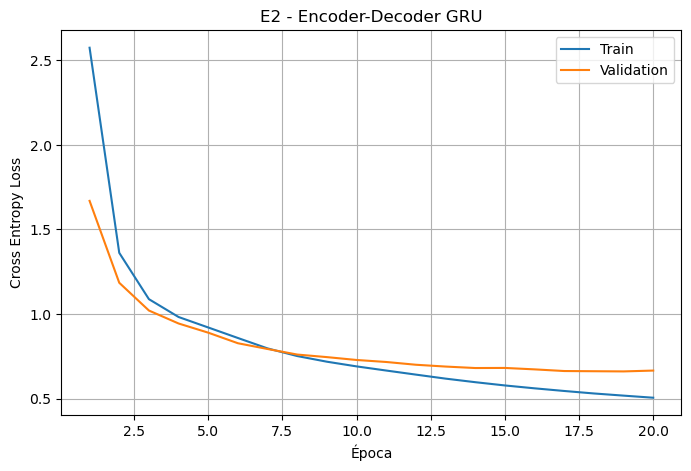

In [39]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(history_e2["train_loss"]) + 1),
    history_e2["train_loss"],
    label="Train"
)

plt.plot(
    range(1, len(history_e2["val_loss"]) + 1),
    history_e2["val_loss"],
    label="Validation"
)

plt.xlabel("Época")
plt.ylabel("Cross Entropy Loss")
plt.title("E2 - Encoder-Decoder GRU")
plt.legend()
plt.grid()

plt.savefig(
    BASE / "E2_curva_loss.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [40]:
metricas_e2 = evaluar_modelo(
    model_e2,
    valid_loader
)

print(metricas_e2)

{'loss': 0.660780277732919, 'acc_nota': 0.8129773421588594, 'acc_paso': 0.6348650712830958}


In [41]:
params_e2 = sum(
    p.numel()
    for p in model_e2.parameters()
    if p.requires_grad
)

print("Parámetros entrenables E2:", params_e2)

Parámetros entrenables E2: 231424


In [42]:
with mlflow.start_run(run_name="E2_GRU"):

    mlflow.log_param("experimento", "E2")
    mlflow.log_param("arquitectura", "Encoder-Decoder GRU")
    mlflow.log_param("atencion", False)
    mlflow.log_param("num_layers", NUM_LAYERS)
    mlflow.log_param("hidden_dim", HIDDEN_DIM)
    mlflow.log_param("embedding_dim", EMBED_DIM)
    mlflow.log_param("learning_rate", 1e-3)
    mlflow.log_param("batch_size", BATCH_SIZE)
    mlflow.log_param("max_epochs", MAX_EPOCHS)
    mlflow.log_param("seed", SEED)
    mlflow.log_param("context_steps", 32)
    mlflow.log_param("horizon_steps", 16)

    for i, (tr, va) in enumerate(
        zip(history_e2["train_loss"], history_e2["val_loss"]),
        start=1
    ):
        mlflow.log_metric("train_loss", tr, step=i)
        mlflow.log_metric("val_loss", va, step=i)

    mlflow.log_metric("best_epoch", best_epoch_e2)
    mlflow.log_metric("best_val_loss", metricas_e2["loss"])
    mlflow.log_metric("val_acc_nota", metricas_e2["acc_nota"])
    mlflow.log_metric("val_acc_paso", metricas_e2["acc_paso"])
    mlflow.log_metric("parametros_entrenables", params_e2)
    mlflow.log_metric("tiempo_segundos", tiempo_e2)

    mlflow.log_param("device", str(device))

    mlflow.log_artifact(
        str(BASE / "E2_curva_loss.png"),
        artifact_path="graficas"
    )

    mlflow.log_artifact(
        str(BASE / "E2_best_gru.pt"),
        artifact_path="checkpoints"
    )

print("E2 registrado en MLflow")

E2 registrado en MLflow


In [43]:
runs = mlflow.search_runs(
    experiment_ids=[exp.experiment_id]
)

display(
    runs[
        [
            "tags.mlflow.runName",
            "metrics.best_val_loss",
            "metrics.val_acc_nota",
            "metrics.val_acc_paso",
            "metrics.parametros_entrenables",
            "metrics.tiempo_segundos"
        ]
    ]
)

,tags.mlflow.runName,metrics.best_val_loss,metrics.val_acc_nota,metrics.val_acc_paso,metrics.parametros_entrenables,metrics.tiempo_segundos
0,E2_GRU,0.660780,0.812977,0.634865,231424.0,112.713457
1,E1_LSTM,0.760435,0.788235,0.597632,281088.0,156.978956


In [44]:
class AdditiveAttention(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()

        self.W_enc = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.W_dec = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.v = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, encoder_outputs, decoder_hidden):
        # encoder_outputs: (batch, 32, hidden)
        # decoder_hidden:   (batch, hidden)

        dec = self.W_dec(decoder_hidden).unsqueeze(1)

        scores = self.v(
            torch.tanh(
                self.W_enc(encoder_outputs) + dec
            )
        ).squeeze(-1)

        # (batch, 32)
        attention_weights = torch.softmax(scores, dim=1)

        # contexto: suma ponderada de estados del encoder
        context = torch.bmm(
            attention_weights.unsqueeze(1),
            encoder_outputs
        ).squeeze(1)

        # context: (batch, hidden)

        return context, attention_weights

In [45]:
class DecoderGRUAttention(nn.Module):
    def __init__(
        self,
        vocab_size=128,
        embed_dim=16,
        hidden_dim=128,
        num_layers=1
    ):
        super().__init__()

        self.embeddings = nn.ModuleList([
            nn.Embedding(vocab_size, embed_dim)
            for _ in range(NUM_VOICES)
        ])

        self.attention = AdditiveAttention(hidden_dim)

        self.gru = nn.GRU(
            input_size=(embed_dim * NUM_VOICES) + hidden_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True
        )

        self.output_layers = nn.ModuleList([
            nn.Linear(hidden_dim, vocab_size)
            for _ in range(NUM_VOICES)
        ])

    def forward_step(
        self,
        x_step,
        h,
        encoder_outputs
    ):
        emb = [
            self.embeddings[v](x_step[:, v])
            for v in range(NUM_VOICES)
        ]

        x_emb = torch.cat(emb, dim=-1)

        decoder_hidden = h[-1]

        context, attention_weights = self.attention(
            encoder_outputs,
            decoder_hidden
        )

        gru_input = torch.cat(
            [x_emb, context],
            dim=-1
        ).unsqueeze(1)

        output, h = self.gru(
            gru_input,
            h
        )

        output = output[:, 0, :]

        logits = torch.stack(
            [layer(output) for layer in self.output_layers],
            dim=1
        )

        return logits, h, attention_weights

In [46]:
class Seq2SeqGRUAttention(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = EncoderGRU()
        self.decoder = DecoderGRUAttention()

    def forward(
        self,
        x,
        y=None,
        teacher_forcing=True,
        return_attention=False
    ):
        encoder_outputs, h = self.encoder(x)

        decoder_input = x[:, -1, :]

        logits_steps = []
        attention_steps = []

        for t in range(OUTPUT_STEPS):

            logits, h, attn = self.decoder.forward_step(
                decoder_input,
                h,
                encoder_outputs
            )

            logits_steps.append(logits)
            attention_steps.append(attn)

            if teacher_forcing and y is not None:
                decoder_input = y[:, t, :]
            else:
                decoder_input = logits.argmax(dim=-1)

        logits_all = torch.stack(
            logits_steps,
            dim=1
        )

        if return_attention:
            attention_all = torch.stack(
                attention_steps,
                dim=1
            )

            return logits_all, attention_all

        return logits_all

In [47]:
torch.manual_seed(42)

model_e3 = Seq2SeqGRUAttention().to(device)

xb, yb = next(iter(train_loader))

xb = xb.to(device)
yb = yb.to(device)

with torch.no_grad():
    logits, attn = model_e3(
        xb,
        yb,
        teacher_forcing=True,
        return_attention=True
    )

print("Logits:", logits.shape)
print("Atención:", attn.shape)

Logits: torch.Size([64, 16, 4, 128])
Atención: torch.Size([64, 16, 32])


In [48]:
resultado_e3_train = entrenar_modelo(
    model_e3,
    train_loader,
    valid_loader,
    "E3_GRU_ATENCION"
)

Epoch 01 | Train Loss: 2.6245 | Val Loss: 1.9388 | Acc Nota: 0.5030 | Acc Paso: 0.1104
  -> Nuevo mejor checkpoint
Epoch 02 | Train Loss: 1.5600 | Val Loss: 1.3062 | Acc Nota: 0.6990 | Acc Paso: 0.4201
  -> Nuevo mejor checkpoint
Epoch 03 | Train Loss: 1.1576 | Val Loss: 1.0665 | Acc Nota: 0.7460 | Acc Paso: 0.5241
  -> Nuevo mejor checkpoint
Epoch 04 | Train Loss: 1.0054 | Val Loss: 0.9609 | Acc Nota: 0.7658 | Acc Paso: 0.5762
  -> Nuevo mejor checkpoint
Epoch 05 | Train Loss: 0.9210 | Val Loss: 0.8898 | Acc Nota: 0.7742 | Acc Paso: 0.5938
  -> Nuevo mejor checkpoint
Epoch 06 | Train Loss: 0.8574 | Val Loss: 0.8442 | Acc Nota: 0.7774 | Acc Paso: 0.5959
  -> Nuevo mejor checkpoint
Epoch 07 | Train Loss: 0.8086 | Val Loss: 0.8090 | Acc Nota: 0.7794 | Acc Paso: 0.5998
  -> Nuevo mejor checkpoint
Epoch 08 | Train Loss: 0.7672 | Val Loss: 0.7789 | Acc Nota: 0.7834 | Acc Paso: 0.6016
  -> Nuevo mejor checkpoint
Epoch 09 | Train Loss: 0.7315 | Val Loss: 0.7582 | Acc Nota: 0.7861 | Acc Paso: 

In [49]:
model_e3 = resultado_e3_train["model"]
history_e3 = resultado_e3_train["history"]
best_state_e3 = resultado_e3_train["best_state"]
best_epoch_e3 = resultado_e3_train["best_epoch"]
best_val_loss_e3 = resultado_e3_train["best_val_loss"]
tiempo_e3 = resultado_e3_train["tiempo"]

print("\n===== RESULTADO E3 =====")
print("Mejor época:", best_epoch_e3)
print("Mejor Val Loss:", best_val_loss_e3)
print("Tiempo total:", tiempo_e3, "segundos")


===== RESULTADO E3 =====
Mejor época: 16
Mejor Val Loss: 0.7082186477247421
Tiempo total: 197.6394305229187 segundos


In [50]:
torch.save(
    {
        "model_state_dict": best_state_e3,
        "best_epoch": best_epoch_e3,
        "best_val_loss": best_val_loss_e3,
        "config": {
            "architecture": "GRU + atención aditiva",
            "vocab_size": VOCAB_SIZE,
            "embed_dim": EMBED_DIM,
            "hidden_dim": HIDDEN_DIM,
            "num_layers": NUM_LAYERS,
            "batch_size": BATCH_SIZE,
            "learning_rate": 1e-3,
            "seed": SEED,
            "context_steps": 32,
            "output_steps": 16
        }
    },
    BASE / "E3_best_gru_attention.pt"
)

print("Checkpoint E3 guardado.")

Checkpoint E3 guardado.


In [51]:
print("Mejor época E3:", best_epoch_e3)
print("Mejor Val Loss E3:", best_val_loss_e3)
print("Tiempo E3:", tiempo_e3)

Mejor época E3: 16
Mejor Val Loss E3: 0.7082186477247421
Tiempo E3: 197.6394305229187


In [52]:
metricas_e3 = evaluar_modelo(
    model_e3,
    valid_loader
)

print(metricas_e3)

{'loss': 0.7082186477247421, 'acc_nota': 0.7937722759674134, 'acc_paso': 0.6097886965376782}


In [53]:
params_e3 = sum(
    p.numel()
    for p in model_e3.parameters()
    if p.requires_grad
)

print("Parámetros entrenables E3:", params_e3)

Parámetros entrenables E3: 313472


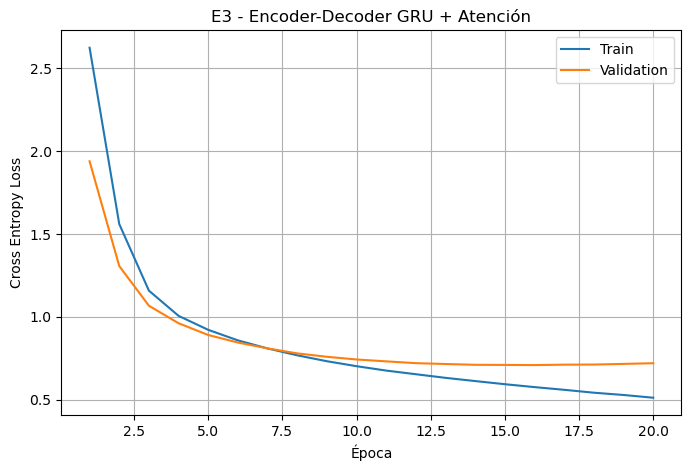

In [54]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(history_e3["train_loss"]) + 1),
    history_e3["train_loss"],
    label="Train"
)

plt.plot(
    range(1, len(history_e3["val_loss"]) + 1),
    history_e3["val_loss"],
    label="Validation"
)

plt.xlabel("Época")
plt.ylabel("Cross Entropy Loss")
plt.title("E3 - Encoder-Decoder GRU + Atención")
plt.legend()
plt.grid()

plt.savefig(
    BASE / "E3_curva_loss.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [55]:
with mlflow.start_run(run_name="E3_GRU_ATENCION"):

    mlflow.log_param("experimento", "E3")
    mlflow.log_param("arquitectura", "Encoder-Decoder GRU + atención aditiva")
    mlflow.log_param("atencion", True)
    mlflow.log_param("num_layers", NUM_LAYERS)
    mlflow.log_param("hidden_dim", HIDDEN_DIM)
    mlflow.log_param("embedding_dim", EMBED_DIM)
    mlflow.log_param("learning_rate", 1e-3)
    mlflow.log_param("batch_size", BATCH_SIZE)
    mlflow.log_param("max_epochs", MAX_EPOCHS)
    mlflow.log_param("seed", SEED)
    mlflow.log_param("context_steps", 32)
    mlflow.log_param("horizon_steps", 16)

    for i, (tr, va) in enumerate(
        zip(history_e3["train_loss"], history_e3["val_loss"]),
        start=1
    ):
        mlflow.log_metric("train_loss", tr, step=i)
        mlflow.log_metric("val_loss", va, step=i)

    mlflow.log_metric("best_epoch", best_epoch_e3)
    mlflow.log_metric("best_val_loss", metricas_e3["loss"])
    mlflow.log_metric("val_acc_nota", metricas_e3["acc_nota"])
    mlflow.log_metric("val_acc_paso", metricas_e3["acc_paso"])
    mlflow.log_metric("parametros_entrenables", params_e3)
    mlflow.log_metric("tiempo_segundos", tiempo_e3)

    mlflow.log_param("device", str(device))

    mlflow.log_artifact(
        str(BASE / "E3_curva_loss.png"),
        artifact_path="graficas"
    )

    mlflow.log_artifact(
        str(BASE / "E3_best_gru_attention.pt"),
        artifact_path="checkpoints"
    )

print("E3 registrado en MLflow")

E3 registrado en MLflow


In [56]:
runs = mlflow.search_runs(
    experiment_ids=[exp.experiment_id]
)

display(
    runs[
        [
            "tags.mlflow.runName",
            "metrics.best_val_loss",
            "metrics.val_acc_nota",
            "metrics.val_acc_paso",
            "metrics.parametros_entrenables",
            "metrics.tiempo_segundos"
        ]
    ]
)

,tags.mlflow.runName,metrics.best_val_loss,metrics.val_acc_nota,metrics.val_acc_paso,metrics.parametros_entrenables,metrics.tiempo_segundos
0,E3_GRU_ATENCION,0.708219,0.793772,0.609789,313472.0,197.639431
1,E2_GRU,0.660780,0.812977,0.634865,231424.0,112.713457
2,E1_LSTM,0.760435,0.788235,0.597632,281088.0,156.978956


In [57]:
class Seq2SeqGRUConfig(nn.Module):
    def __init__(self, hidden_dim=128):
        super().__init__()

        self.encoder = EncoderGRU(
            vocab_size=VOCAB_SIZE,
            embed_dim=EMBED_DIM,
            hidden_dim=hidden_dim,
            num_layers=NUM_LAYERS
        )

        self.decoder = DecoderGRU(
            vocab_size=VOCAB_SIZE,
            embed_dim=EMBED_DIM,
            hidden_dim=hidden_dim,
            num_layers=NUM_LAYERS
        )

    def forward(self, x, y=None, teacher_forcing=True):

        encoder_outputs, h = self.encoder(x)

        decoder_input = x[:, -1, :]

        logits_steps = []

        for t in range(OUTPUT_STEPS):

            logits, h = self.decoder.forward_step(
                decoder_input,
                h
            )

            logits_steps.append(logits)

            if teacher_forcing and y is not None:
                decoder_input = y[:, t, :]
            else:
                decoder_input = logits.argmax(dim=-1)

        return torch.stack(logits_steps, dim=1)

In [58]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

model_e4 = Seq2SeqGRUConfig(
    hidden_dim=256
).to(device)

print(model_e4)

Seq2SeqGRUConfig(
  (encoder): EncoderGRU(
    (embeddings): ModuleList(
      (0-3): 4 x Embedding(128, 16)
    )
    (gru): GRU(64, 256, batch_first=True)
  )
  (decoder): DecoderGRU(
    (embeddings): ModuleList(
      (0-3): 4 x Embedding(128, 16)
    )
    (gru): GRU(64, 256, batch_first=True)
    (output_layers): ModuleList(
      (0-3): 4 x Linear(in_features=256, out_features=128, bias=True)
    )
  )
)


In [59]:
xb, yb = next(iter(train_loader))

xb = xb.to(device)
yb = yb.to(device)

with torch.no_grad():
    logits = model_e4(
        xb,
        yb,
        teacher_forcing=True
    )

print("X:", xb.shape)
print("Y:", yb.shape)
print("Logits:", logits.shape)

X: torch.Size([64, 32, 4])
Y: torch.Size([64, 16, 4])
Logits: torch.Size([64, 16, 4, 128])


In [60]:
resultado_e4_train = entrenar_modelo(
    model_e4,
    train_loader,
    valid_loader,
    "E4_GRU_H256"
)

Epoch 01 | Train Loss: 2.1710 | Val Loss: 1.3243 | Acc Nota: 0.6861 | Acc Paso: 0.3901
  -> Nuevo mejor checkpoint
Epoch 02 | Train Loss: 1.1237 | Val Loss: 1.0123 | Acc Nota: 0.7578 | Acc Paso: 0.5615
  -> Nuevo mejor checkpoint
Epoch 03 | Train Loss: 0.9532 | Val Loss: 0.9018 | Acc Nota: 0.7738 | Acc Paso: 0.6016
  -> Nuevo mejor checkpoint
Epoch 04 | Train Loss: 0.8416 | Val Loss: 0.7956 | Acc Nota: 0.7831 | Acc Paso: 0.6145
  -> Nuevo mejor checkpoint
Epoch 05 | Train Loss: 0.7514 | Val Loss: 0.7408 | Acc Nota: 0.7902 | Acc Paso: 0.6225
  -> Nuevo mejor checkpoint
Epoch 06 | Train Loss: 0.6972 | Val Loss: 0.7073 | Acc Nota: 0.7955 | Acc Paso: 0.6232
  -> Nuevo mejor checkpoint
Epoch 07 | Train Loss: 0.6579 | Val Loss: 0.6833 | Acc Nota: 0.8012 | Acc Paso: 0.6255
  -> Nuevo mejor checkpoint
Epoch 08 | Train Loss: 0.6200 | Val Loss: 0.6554 | Acc Nota: 0.8104 | Acc Paso: 0.6341
  -> Nuevo mejor checkpoint
Epoch 09 | Train Loss: 0.5806 | Val Loss: 0.6350 | Acc Nota: 0.8156 | Acc Paso: 

In [61]:
model_e4 = resultado_e4_train["model"]
history_e4 = resultado_e4_train["history"]
best_state_e4 = resultado_e4_train["best_state"]
best_epoch_e4 = resultado_e4_train["best_epoch"]
best_val_loss_e4 = resultado_e4_train["best_val_loss"]
tiempo_e4 = resultado_e4_train["tiempo"]

print("\n===== RESULTADO E4 =====")
print("Mejor época:", best_epoch_e4)
print("Mejor Val Loss:", best_val_loss_e4)
print("Tiempo total:", tiempo_e4, "segundos")


===== RESULTADO E4 =====
Mejor época: 13
Mejor Val Loss: 0.6117281633336287
Tiempo total: 141.59326720237732 segundos


In [62]:
torch.save(
    {
        "model_state_dict": best_state_e4,
        "best_epoch": best_epoch_e4,
        "best_val_loss": best_val_loss_e4,
        "config": {
            "architecture": "GRU",
            "vocab_size": VOCAB_SIZE,
            "embed_dim": EMBED_DIM,
            "hidden_dim": 256,
            "num_layers": NUM_LAYERS,
            "batch_size": BATCH_SIZE,
            "learning_rate": 1e-3,
            "seed": SEED,
            "context_steps": 32,
            "output_steps": 16
        }
    },
    BASE / "E4_best_gru_h256.pt"
)

print("Checkpoint E4 guardado.")

Checkpoint E4 guardado.


In [63]:
metricas_e4 = evaluar_modelo(
    model_e4,
    valid_loader
)

print(metricas_e4)

{'loss': 0.6117281633336287, 'acc_nota': 0.8186577138492872, 'acc_paso': 0.6416751527494908}


In [64]:
params_e4 = sum(
    p.numel()
    for p in model_e4.parameters()
    if p.requires_grad
)

print("Parámetros entrenables E4:", params_e4)

Parámetros entrenables E4: 642560


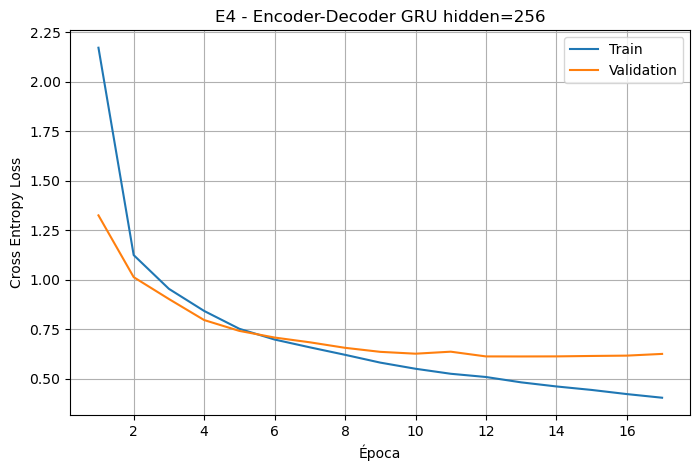

In [65]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(history_e4["train_loss"]) + 1),
    history_e4["train_loss"],
    label="Train"
)

plt.plot(
    range(1, len(history_e4["val_loss"]) + 1),
    history_e4["val_loss"],
    label="Validation"
)

plt.xlabel("Época")
plt.ylabel("Cross Entropy Loss")
plt.title("E4 - Encoder-Decoder GRU hidden=256")
plt.legend()
plt.grid()

plt.savefig(
    BASE / "E4_curva_loss.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [66]:
with mlflow.start_run(run_name="E4_GRU_H256"):

    mlflow.log_param("experimento", "E4")
    mlflow.log_param("arquitectura", "Encoder-Decoder GRU")
    mlflow.log_param("atencion", False)
    mlflow.log_param("num_layers", NUM_LAYERS)
    mlflow.log_param("hidden_dim", 256)
    mlflow.log_param("embedding_dim", EMBED_DIM)
    mlflow.log_param("learning_rate", 1e-3)
    mlflow.log_param("batch_size", BATCH_SIZE)
    mlflow.log_param("max_epochs", MAX_EPOCHS)
    mlflow.log_param("seed", SEED)
    mlflow.log_param("context_steps", 32)
    mlflow.log_param("horizon_steps", 16)

    for i, (tr, va) in enumerate(
        zip(history_e4["train_loss"], history_e4["val_loss"]),
        start=1
    ):
        mlflow.log_metric("train_loss", tr, step=i)
        mlflow.log_metric("val_loss", va, step=i)

    mlflow.log_metric("best_epoch", best_epoch_e4)
    mlflow.log_metric("best_val_loss", metricas_e4["loss"])
    mlflow.log_metric("val_acc_nota", metricas_e4["acc_nota"])
    mlflow.log_metric("val_acc_paso", metricas_e4["acc_paso"])
    mlflow.log_metric("parametros_entrenables", params_e4)
    mlflow.log_metric("tiempo_segundos", tiempo_e4)

    mlflow.log_param("device", str(device))

    mlflow.log_artifact(
        str(BASE / "E4_curva_loss.png"),
        artifact_path="graficas"
    )

    mlflow.log_artifact(
        str(BASE / "E4_best_gru_h256.pt"),
        artifact_path="checkpoints"
    )

print("E4 registrado en MLflow")

E4 registrado en MLflow


In [67]:
runs = mlflow.search_runs(
    experiment_ids=[exp.experiment_id]
)

display(
    runs[
        [
            "tags.mlflow.runName",
            "metrics.best_val_loss",
            "metrics.val_acc_nota",
            "metrics.val_acc_paso",
            "metrics.parametros_entrenables",
            "metrics.tiempo_segundos"
        ]
    ]
)

,tags.mlflow.runName,metrics.best_val_loss,metrics.val_acc_nota,metrics.val_acc_paso,metrics.parametros_entrenables,metrics.tiempo_segundos
0,E4_GRU_H256,0.611728,0.818658,0.641675,642560.0,141.593267
1,E3_GRU_ATENCION,0.708219,0.793772,0.609789,313472.0,197.639431
2,E2_GRU,0.660780,0.812977,0.634865,231424.0,112.713457
3,E1_LSTM,0.760435,0.788235,0.597632,281088.0,156.978956


In [68]:
metricas_test_e4 = evaluar_modelo(
    model_e4,
    test_loader
)

print("===== TEST E4 =====")
print("Test Loss:", metricas_test_e4["loss"])
print("Test Acc Nota:", metricas_test_e4["acc_nota"])
print("Test Acc Paso:", metricas_test_e4["acc_paso"])

===== TEST E4 =====
Test Loss: 0.6313386686242063
Test Acc Nota: 0.8137982195845698
Test Acc Paso: 0.6261745796241345


In [69]:
runs = mlflow.search_runs(
    experiment_ids=[exp.experiment_id]
)

run_e4 = runs[
    runs["tags.mlflow.runName"] == "E4_GRU_H256"
].iloc[0]

run_id_e4 = run_e4["run_id"]

print("Run ID E4:", run_id_e4)

Run ID E4: b770a63a0ea9407f9942ba733e4d501b


In [70]:
with mlflow.start_run(run_id=run_id_e4):

    mlflow.log_metric(
        "test_loss",
        metricas_test_e4["loss"]
    )

    mlflow.log_metric(
        "test_acc_nota",
        metricas_test_e4["acc_nota"]
    )

    mlflow.log_metric(
        "test_acc_paso",
        metricas_test_e4["acc_paso"]
    )

print("Métricas de test registradas.")

Métricas de test registradas.


In [71]:
import torch.nn.functional as F

def generar_bloque(model, contexto, temperature=1.0, pasos=16):
    """
    contexto: tensor (1, 32, 4)
    devuelve: tensor (1, pasos, 4)
    """

    model.eval()

    with torch.no_grad():

        encoder_outputs, h = model.encoder(contexto)

        decoder_input = contexto[:, -1, :]

        generados = []

        for _ in range(pasos):

            logits, h = model.decoder.forward_step(
                decoder_input,
                h
            )

            # logits: (1, 4, 128)

            probs = F.softmax(
                logits / temperature,
                dim=-1
            )

            notas = []

            for voz in range(NUM_VOICES):

                nota = torch.multinomial(
                    probs[:, voz, :],
                    num_samples=1
                )

                notas.append(nota)

            # (1, 4)
            siguiente = torch.cat(
                notas,
                dim=1
            )

            generados.append(siguiente)

            decoder_input = siguiente

        return torch.stack(
            generados,
            dim=1
        )

In [72]:
def generar_continuacion(
    model,
    contexto_inicial,
    total_steps=32,
    temperature=1.0
):
    contexto = contexto_inicial.clone()

    generados_totales = []

    faltan = total_steps

    while faltan > 0:

        pasos_bloque = min(
            16,
            faltan
        )

        bloque = generar_bloque(
            model,
            contexto,
            temperature=temperature,
            pasos=pasos_bloque
        )

        generados_totales.append(
            bloque
        )

        # Contexto + nuevo bloque
        secuencia_completa = torch.cat(
            [contexto, bloque],
            dim=1
        )

        # Mantener últimos 32 pasos
        contexto = secuencia_completa[
            :, -32:, :
        ]

        faltan -= pasos_bloque

    return torch.cat(
        generados_totales,
        dim=1
    )

In [73]:
archivos_valid = sorted(
    VALID_DIR.glob("*.csv")
)

archivo_1 = archivos_valid[0]
archivo_2 = archivos_valid[1]

coro_1 = pd.read_csv(archivo_1)
coro_2 = pd.read_csv(archivo_2)

print("Coral 1:", archivo_1.name)
print("Coral 2:", archivo_2.name)

Coral 1: chorale_229.csv
Coral 2: chorale_230.csv


In [74]:
contexto_1 = torch.tensor(
    coro_1[
        ["note0", "note1", "note2", "note3"]
    ].iloc[:32].values,
    dtype=torch.long
).unsqueeze(0).to(device)

contexto_2 = torch.tensor(
    coro_2[
        ["note0", "note1", "note2", "note3"]
    ].iloc[:32].values,
    dtype=torch.long
).unsqueeze(0).to(device)

print(contexto_1.shape)
print(contexto_2.shape)

torch.Size([1, 32, 4])
torch.Size([1, 32, 4])


In [75]:
GEN_SEED = 1234

torch.manual_seed(GEN_SEED)

generado_1 = generar_continuacion(
    model_e4,
    contexto_1,
    total_steps=32,
    temperature=1.0
)

torch.manual_seed(GEN_SEED)

generado_2 = generar_continuacion(
    model_e4,
    contexto_2,
    total_steps=32,
    temperature=1.0
)

print("Generado 1:", generado_1.shape)
print("Generado 2:", generado_2.shape)

Generado 1: torch.Size([1, 32, 4])
Generado 2: torch.Size([1, 32, 4])


In [76]:
print(
    "Rango generado 1:",
    generado_1.min().item(),
    generado_1.max().item()
)

print(
    "Rango generado 2:",
    generado_2.min().item(),
    generado_2.max().item()
)

Rango generado 1: 52 79
Rango generado 2: 48 72


In [77]:
!pip install pretty_midi

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 20.1 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pretty_midi]


In [78]:
import pretty_midi

In [79]:
def matriz_a_midi(
    matriz,
    archivo_salida,
    tempo=120
):
    """
    matriz: array/tensor (pasos, 4)
    Cada fila es un paso temporal.
    0 = silencio.
    """

    if torch.is_tensor(matriz):
        matriz = matriz.detach().cpu().numpy()

    midi = pretty_midi.PrettyMIDI(
        initial_tempo=tempo
    )

    # Un instrumento por voz
    instrumentos = []

    for v in range(4):
        instrumento = pretty_midi.Instrument(
            program=0,
            name=f"Voz {v}"
        )
        instrumentos.append(instrumento)
        midi.instruments.append(instrumento)

    # Cada paso es una semicorchea:
    # 60 / (4 * tempo)
    duracion_paso = 60.0 / (4.0 * tempo)

    for voz in range(4):

        inicio_nota = None
        nota_actual = None

        for t in range(len(matriz) + 1):

            if t < len(matriz):
                nota = int(matriz[t, voz])
            else:
                # Forzar cierre de la última nota
                nota = None

            # Si seguimos con la misma nota
            if (
                nota_actual is not None
                and nota == nota_actual
            ):
                continue

            # Cerrar nota anterior
            if nota_actual is not None and nota_actual != 0:

                nota_midi = pretty_midi.Note(
                    velocity=90,
                    pitch=nota_actual,
                    start=inicio_nota * duracion_paso,
                    end=t * duracion_paso
                )

                instrumentos[voz].notes.append(
                    nota_midi
                )

            # Comenzar nueva nota
            if nota is not None:
                nota_actual = nota
                inicio_nota = t

    midi.write(str(archivo_salida))

In [80]:
secuencia_1 = torch.cat(
    [
        contexto_1.cpu(),
        generado_1.cpu()
    ],
    dim=1
).squeeze(0)

secuencia_2 = torch.cat(
    [
        contexto_2.cpu(),
        generado_2.cpu()
    ],
    dim=1
).squeeze(0)

print(secuencia_1.shape)
print(secuencia_2.shape)

torch.Size([64, 4])
torch.Size([64, 4])


In [81]:
TEMPO = 120

matriz_a_midi(
    secuencia_1,
    BASE / "bach_generado_1.mid",
    tempo=TEMPO
)

matriz_a_midi(
    secuencia_2,
    BASE / "bach_generado_2.mid",
    tempo=TEMPO
)

print("MIDI creados.")

MIDI creados.


In [82]:
print(BASE / "bach_generado_1.mid")
print(BASE / "bach_generado_2.mid")

/home/ec2-user/SageMaker/bach_lab/bach_generado_1.mid
/home/ec2-user/SageMaker/bach_lab/bach_generado_2.mid


In [83]:
model_e3.load_state_dict(best_state_e3)
model_e3.eval()

Seq2SeqGRUAttention(
  (encoder): EncoderGRU(
    (embeddings): ModuleList(
      (0-3): 4 x Embedding(128, 16)
    )
    (gru): GRU(64, 128, batch_first=True)
  )
  (decoder): DecoderGRUAttention(
    (embeddings): ModuleList(
      (0-3): 4 x Embedding(128, 16)
    )
    (attention): AdditiveAttention(
      (W_enc): Linear(in_features=128, out_features=128, bias=False)
      (W_dec): Linear(in_features=128, out_features=128, bias=False)
      (v): Linear(in_features=128, out_features=1, bias=False)
    )
    (gru): GRU(192, 128, batch_first=True)
    (output_layers): ModuleList(
      (0-3): 4 x Linear(in_features=128, out_features=128, bias=True)
    )
  )
)

In [84]:
with torch.no_grad():
    logits_e3, atencion_e3 = model_e3(
        contexto_1,
        y=None,
        teacher_forcing=False,
        return_attention=True
    )

print("Logits:", logits_e3.shape)
print("Atención:", atencion_e3.shape)

Logits: torch.Size([1, 16, 4, 128])
Atención: torch.Size([1, 16, 32])


In [85]:
mapa_atencion = atencion_e3[0].cpu().numpy()

print(mapa_atencion.shape)

(16, 32)


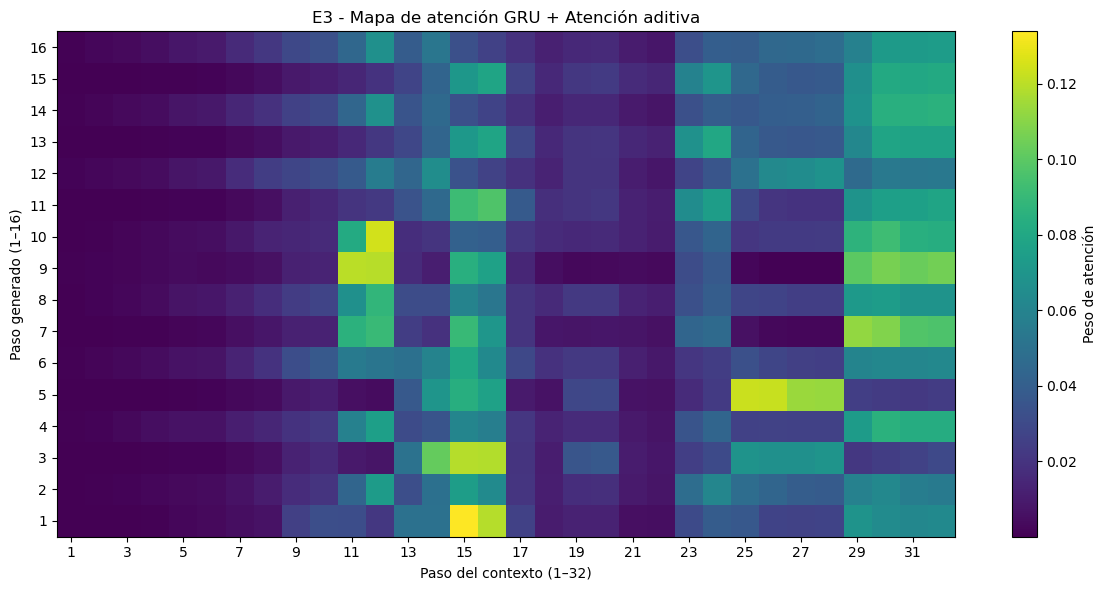

In [86]:
plt.figure(figsize=(12, 6))

plt.imshow(
    mapa_atencion,
    aspect="auto",
    origin="lower"
)

plt.colorbar(
    label="Peso de atención"
)

plt.xlabel("Paso del contexto (1–32)")
plt.ylabel("Paso generado (1–16)")
plt.title(
    "E3 - Mapa de atención GRU + Atención aditiva"
)

plt.xticks(
    range(0, 32, 2),
    range(1, 33, 2)
)

plt.yticks(
    range(16),
    range(1, 17)
)

plt.tight_layout()

plt.savefig(
    BASE / "E3_mapa_atencion.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [87]:
import numpy as np

promedio_atencion = mapa_atencion.mean(axis=0)

top_indices = np.argsort(
    promedio_atencion
)[::-1][:5]

print("Posiciones con mayor atención promedio:")

for idx in top_indices:
    print(
        f"Paso {idx + 1}: "
        f"{promedio_atencion[idx]:.4f}"
    )

Posiciones con mayor atención promedio:
Paso 15: 0.0725
Paso 30: 0.0718
Paso 32: 0.0701
Paso 31: 0.0694
Paso 16: 0.0670


In [88]:
runs = mlflow.search_runs(
    experiment_ids=[exp.experiment_id]
)

run_e3 = runs[
    runs["tags.mlflow.runName"] == "E3_GRU_ATENCION"
].iloc[0]

run_id_e3 = run_e3["run_id"]

print("Run ID E3:", run_id_e3)

Run ID E3: 92bb07aae0a14e13a780fb4df5cdbbeb


In [89]:
with mlflow.start_run(run_id=run_id_e3):

    mlflow.log_artifact(
        str(BASE / "E3_mapa_atencion.png"),
        artifact_path="atencion"
    )

print("Mapa de atención registrado en MLflow.")

Mapa de atención registrado en MLflow.


In [90]:
import mlflow.pytorch
from mlflow import MlflowClient

MODEL_NAME = "bach-chorales-mariana"

In [92]:
import mlflow.pytorch
from mlflow import MlflowClient

MODEL_NAME = "bach-chorales-mariana"

with mlflow.start_run(run_id=run_id_e4):

    mlflow.pytorch.log_model(
        pytorch_model=model_e4,
        name="model",
        registered_model_name=MODEL_NAME,
        serialization_format="pickle"
    )

print("Modelo E4 registrado correctamente.")

2026/10/27 03:50:34 WARNING mlflow.pytorch: Saving pytorch model by Pickle or CloudPickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is to set `serialization_format` to 'pt2' to save the PyTorch model using the safe graph model format.
2026/10/27 03:50:34 WARNING mlflow.utils.requirements_utils: Found torch version (2.10.0+cu128) contains a local version label (+cu128). MLflow logged a pip requirement for this package as 'torch==2.10.0' without the local version label to make it installable from PyPI. To specify pip requirements containing local version labels, please use `conda_env` or `pip_requirements`.
2026/10/27 03:50:54 WARNING mlflow.utils.requirements_utils: Found torch version (2.10.0+cu128) contains a local version label (+cu128). MLflow logged a pip requirement for this package as 'torch==2.10.0' without the local version la

Modelo E4 registrado correctamente.


Successfully registered model 'bach-chorales-mariana'.
Created version '1' of model 'bach-chorales-mariana'.


In [93]:
client = MlflowClient()

versions = client.search_model_versions(
    f"name='{MODEL_NAME}'"
)

for v in versions:
    print(
        "Version:", v.version,
        "| Run ID:", v.run_id
    )

Version: 1 | Run ID: b770a63a0ea9407f9942ba733e4d501b


In [94]:
client.set_registered_model_alias(
    MODEL_NAME,
    "champion",
    1
)

print("Alias champion asignado.")

Alias champion asignado.


In [95]:
champion = client.get_model_version_by_alias(
    MODEL_NAME,
    "champion"
)

print("Modelo:", champion.name)
print("Versión:", champion.version)
print("Run ID:", champion.run_id)

Modelo: bach-chorales-mariana
Versión: 1
Run ID: b770a63a0ea9407f9942ba733e4d501b


In [96]:
model_champion = mlflow.pytorch.load_model(
    "models:/bach-chorales-mariana@champion",
    map_location="cpu"
)

model_champion.eval()

print("Champion cargado correctamente.")

Champion cargado correctamente.


In [97]:
xb_test, yb_test = next(iter(test_loader))

xb_test = xb_test[:2]

with torch.no_grad():
    logits_champion = model_champion(
        xb_test,
        y=None,
        teacher_forcing=False
    )

print("Forma salida:", logits_champion.shape)

Forma salida: torch.Size([2, 16, 4, 128])


In [98]:
import json

payload_prueba = {
    "seed": contexto_1[0].cpu().tolist(),
    "steps": 32,
    "temperature": 1.0
}

print(json.dumps(payload_prueba, indent=2))

{
  "seed": [
    [
      72,
      67,
      60,
      48
    ],
    [
      72,
      67,
      60,
      48
    ],
    [
      72,
      67,
      60,
      48
    ],
    [
      72,
      67,
      60,
      48
    ],
    [
      72,
      67,
      64,
      48
    ],
    [
      72,
      67,
      64,
      48
    ],
    [
      72,
      67,
      64,
      50
    ],
    [
      72,
      67,
      64,
      50
    ],
    [
      72,
      67,
      64,
      52
    ],
    [
      72,
      67,
      64,
      52
    ],
    [
      72,
      67,
      64,
      53
    ],
    [
      72,
      67,
      64,
      53
    ],
    [
      71,
      67,
      62,
      55
    ],
    [
      71,
      67,
      62,
      55
    ],
    [
      71,
      65,
      62,
      55
    ],
    [
      71,
      65,
      62,
      55
    ],
    [
      69,
      64,
      60,
      45
    ],
    [
      69,
      64,
      60,
      45
    ],
    [
      69,
      64,
      60,
      47
    ]